# 쇼핑몰 고객·상품 데이터 분석 — 단골(VIP) 고객 찾기

**미션:** 이커머스 플랫폼의 상품(수치+텍스트+범주+날짜+이미지) 데이터와 거래 데이터를 분석하여
멀티모달 전처리, 이상치 탐지, EDA, RFM 기반 고객 세분화를 수행한다.

- 분석 파이프라인: `src/pipeline.py`의 `DataAnalyzer` 클래스
- 데이터: `data/products.csv`, `data/product_images.npy`, `data/transactions.csv`
  (출처: 실제 Kaggle 이커머스 공개 데이터의 컬럼 구조를 참고해 재현한 합성 데이터.
  자세한 내용은 README.md의 "데이터 설명" 참고)


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pipeline import DataAnalyzer

plt.rcParams["figure.figsize"] = (7, 4.3)
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.dpi"] = 80
plt.rcParams["axes.unicode_minus"] = False
sns.set_style("whitegrid")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)


## 1. 데이터 로드 및 기본 탐색

In [2]:
da = DataAnalyzer(data_path="../data")
da.load_data()

print("products:", da.products.shape)
print("images  :", da.images.shape)
print("tx      :", da.transactions.shape)


products: (1500, 7)
images  : (1500, 16, 16, 3)
tx      : (5104, 7)


In [3]:
da.products.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   product_id       1500 non-null   int64         
 1   product_name     1500 non-null   str           
 2   category         1500 non-null   str           
 3   price            1500 non-null   float64       
 4   registered_date  1500 non-null   datetime64[us]
 5   stock_qty        1410 non-null   float64       
 6   rating           1440 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(2)
memory usage: 82.2 KB


In [4]:
da.products.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
product_id,1500.0,NaN,NaN,NaN,750.5,1.0,375.75,750.5,1125.25,1500.0,433.157015
product_name,1500,457,미니멀 과일주스,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,1500,8,식품,202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,1500.0,NaN,NaN,NaN,97482.866667,1000.0,19275.0,39450.0,113050.0,1669100.0,138361.471531
registered_date,1500,NaN,NaN,NaN,2024-11-19 03:40:48,2024-01-02 00:00:00,2024-06-12 00:00:00,2024-11-21 00:00:00,2025-04-25 00:00:00,2025-10-11 00:00:00,NaN
stock_qty,1410.0,NaN,NaN,NaN,247.332624,0.0,124.0,242.5,368.75,499.0,142.369772
rating,1440.0,NaN,NaN,NaN,4.078056,2.44,3.79,4.09,4.39,5.0,0.440216


In [5]:
da.products.head()

,product_id,product_name,category,price,registered_date,stock_qty,rating
0,1,미니멀 보조배터리,전자제품,432600.0,2024-10-12,263.0,3.32
1,2,미니멀 드론장난감,완구,23600.0,2025-06-29,225.0,4.55
2,3,슈퍼 니트원피스,의류,67500.0,2025-02-22,46.0,3.56
3,4,프로 원목테이블,가구,289100.0,2024-04-17,379.0,3.53
4,5,슈퍼 노트북거치대,전자제품,255800.0,2025-08-03,248.0,4.31


**해석**
- 상품 데이터는 1,500건 x 7개 컬럼(수치형 3개: `price`, `stock_qty`, `rating` /
  범주형: `category` / 텍스트: `product_name` / 날짜형: `registered_date`)으로 구성되어
  있으며, 여기에 `product_images.npy`의 이미지 배열까지 더하면 4가지 데이터 유형이 모두 포함된다.
- `describe()` 결과 `price`의 평균(약 97,500원)이 중앙값(약 39,000원)보다 훨씬 커서
  분포가 오른쪽으로 크게 치우쳐 있음을 알 수 있다 → 고가 카테고리(전자제품/가구)가
  평균을 끌어올리는 구조이며, 이는 4장 이상치 탐지에서 다시 다룬다.


In [6]:
tx = da.transactions
print(tx.shape)
tx.head()


(5104, 7)


,order_id,customer_id,product_id,order_date,quantity,unit_price,amount
0,739,C0116,1030,2025-05-01,2,16300.0,32600.0
1,443,C0068,466,2025-05-02,2,55800.0,111600.0
2,2607,C0402,862,2025-05-03,1,76500.0,76500.0
3,1738,C0270,1287,2025-05-03,1,340000.0,340000.0
4,4776,C0734,499,2025-05-04,1,26400.0,26400.0


- 거래 데이터는 5,104건으로 `customer_id`, `order_date`, `amount`(=quantity*unit_price)를
  포함해 RFM 계산 조건을 만족한다. 분석 기준일(Recency 기준일)은 최종 거래일로 정의한다.


## 2. 멀티모달 피처 엔지니어링

- **이미지 → 수치**: `image_mean`(평균 밝기), `image_std`(명암 대비)를 NumPy 축 연산
  `images.mean(axis=(1,2,3))`으로 한 번에 계산한다 (반복문 없음).
- **텍스트 → 수치**: 상품명의 단어 수, 글자 길이를 파생 변수로 추가한다.


In [7]:
da.engineer_image_features()
da.engineer_text_features()
da.products[["product_name", "category", "image_mean", "image_std",
             "name_word_count", "name_length"]].head()


,product_name,category,image_mean,image_std,name_word_count,name_length
0,미니멀 보조배터리,전자제품,120.040365,36.091856,2,9
1,미니멀 드론장난감,완구,187.628906,28.713456,2,9
2,슈퍼 니트원피스,의류,158.738281,19.566806,2,8
3,프로 원목테이블,가구,109.425781,25.845892,2,8
4,슈퍼 노트북거치대,전자제품,118.869792,34.467319,2,9


/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/906264396.py:7: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/906264396.py:7: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/906264396.py:7: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/906264396.py:7: UserWarning: Glyph 54408 (\N{HANGUL SYLLABLE PUM}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/906264396.py:7: UserWarning: Glyph 50756 (\N{HANGUL SYLLABLE WAN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/906264396.py:7: UserWarning: Gl

/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47448 (\N{HANGUL SYLLABLE RYU}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 52852 (\N{HANGUL SYLLABLE KA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pyl

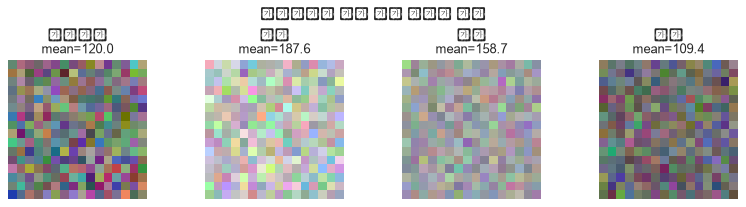

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(10, 2.6))
for i in range(4):
    axes[i].imshow(da.images[i])
    axes[i].set_title(f"{da.products.loc[i,'category']}\nmean={da.products.loc[i,'image_mean']:.1f}")
    axes[i].axis("off")
plt.suptitle("카테고리별 합성 상품 썸네일 예시")
plt.tight_layout()
plt.show()


**해석**
- `image_mean`(평균 밝기)은 카테고리마다 뚜렷이 다르게 설계되어 있다(도서 계열이 밝고,
  전자제품/가구 계열이 어둡게 생성). 뒤의 상관분석에서 `image_mean`과 `price`의 관계를
  정량적으로 확인한다.


## 3. 결측치 처리 (그룹별 대치)

In [9]:
missing_before = da.products.isna().sum()
missing_before[missing_before > 0]


stock_qty    90
rating       60
dtype: int64

In [10]:
summary = da.handle_missing_values(strategy="group_mean", group_col="category",
                                    columns=["stock_qty", "rating"])
summary


,column,missing_before,missing_after
0,stock_qty,90,0
1,rating,60,0


In [11]:
da.products.isna().sum().sum()  # 처리 후 전체 결측치 개수

np.int64(0)

**해석**
- `stock_qty` 90건, `rating` 60건의 결측을 **카테고리별 평균**으로 대치했다. 전체
  평균이 아닌 카테고리별 평균을 쓰는 이유는 예를 들어 `가구`와 `도서`의 평균 재고 수준이
  다르기 때문에(카테고리 특성 반영), 그룹 평균이 전체 평균보다 더 정확한 추정치이기
  때문이다.
- 처리 후 두 컬럼의 결측치는 0건으로, 이후 통계/시각화 분석에 전체 1,500건을 그대로
  사용할 수 있다.


## 4. 이상치 탐지 (IQR) — 처리 전후 분포 비교

In [12]:
outliers = da.detect_outliers("price", threshold=1.5)
print(f"이상치 건수: {len(outliers)} / 전체 {len(da.products)} ({len(outliers)/len(da.products)*100:.1f}%)")
outliers["category"].value_counts()


이상치 건수: 201 / 전체 1500 (13.4%)


category
전자제품    128
가구       68
스포츠       4
완구        1
Name: count, dtype: int64

In [13]:
capped_col = da.cap_outliers("price", threshold=1.5)
capped_col

'price_capped'

/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: UserWarning: Glyph 52376 (\N{HANGUL SYLLABLE CEO}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: U

/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: UserWarning: Glyph 48149 (\N{HANGUL SYLLABLE BAG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1484698097.py:10: User

/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53364 (\N{HANGUL SYLLABLE KEUL}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54609 (\N{HANGUL SYLLABLE PING}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/p

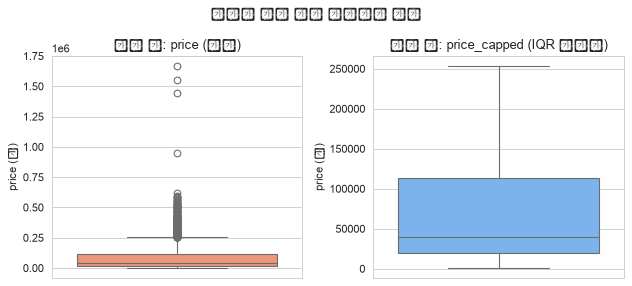

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
sns.boxplot(y=da.products["price"], ax=axes[0], color="#ff8c69")
axes[0].set_title("처리 전: price (원본)")
axes[0].set_ylabel("price (원)")

sns.boxplot(y=da.products[capped_col], ax=axes[1], color="#69b3ff")
axes[1].set_title("처리 후: price_capped (IQR 클리핑)")
axes[1].set_ylabel("price (원)")
plt.suptitle("이상치 처리 전후 박스플롯 비교")
plt.tight_layout()
plt.show()


**해석**
- `price` 기준 IQR(threshold=1.5) 이상치는 201건(전체의 13.4%)으로 비교적 높은 비율인데,
  `value_counts()`로 보면 대부분 `전자제품`/`가구`처럼 원래 고가인 카테고리에 몰려 있다.
  즉 데이터 입력 오류라기보다 **카테고리별 가격대가 크게 다른 구조**가 원인이며,
  실무에서는 카테고리별로 IQR을 따로 적용하는 것이 더 적절하다는 시사점을 얻을 수 있다.
- 박스플롯 비교에서 클리핑(`price_capped`) 후 상단 수염(whisker) 위쪽의 극단치들이
  사라지고 박스 자체의 위치는 거의 그대로 유지되어, 중심 경향은 보존하면서 극단값만
  눌렀음을 확인할 수 있다.


## 5. 통계 분석

In [15]:
num_cols = ["price", "rating", "stock_qty", "image_mean", "image_std", "name_length"]
da.summary_statistics(num_cols)


,mean,median,std,q1,q3
price,97482.866667,39450.000000,138361.471531,19275.000000,113050.000000
rating,4.079332,4.090000,0.433994,3.790000,4.390000
stock_qty,247.336253,248.204301,138.039638,132.000000,363.250000
image_mean,164.976848,161.111328,38.600274,121.581380,190.946615
image_std,21.642629,20.838962,7.340835,15.759394,26.309556
name_length,8.010000,8.000000,1.096678,7.000000,9.000000


In [16]:
corr = da.correlation_matrix(num_cols)
corr


,price,rating,stock_qty,image_mean,image_std,name_length
price,1.000000,-0.163180,0.010863,-0.624456,0.578883,0.322360
rating,-0.163180,1.000000,0.042665,0.344741,-0.199713,-0.085233
stock_qty,0.010863,0.042665,1.000000,-0.013175,0.018801,0.041333
image_mean,-0.624456,0.344741,-0.013175,1.000000,-0.717733,-0.360702
image_std,0.578883,-0.199713,0.018801,-0.717733,1.000000,0.406965
name_length,0.322360,-0.085233,0.041333,-0.360702,0.406965,1.000000


/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/874570750.py:4: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/874570750.py:4: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/874570750.py:4: UserWarning: Glyph 54805 (\N{HANGUL SYLLABLE HYEONG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/874570750.py:4: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/874570750.py:4: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/874570750.py:4: UserWarnin

/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54805 (\N{HANGUL SYLLABLE HYEONG}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/co

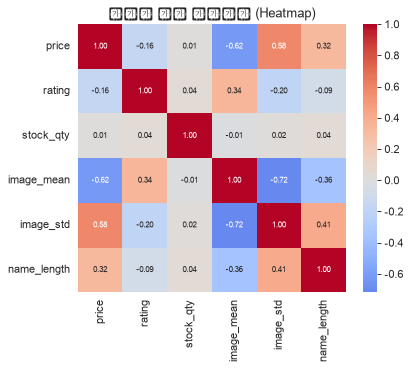

In [17]:
plt.figure(figsize=(5.5, 4.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, annot_kws={"size": 7})
plt.title("수치형 변수 상관행렬 (Heatmap)")
plt.tight_layout()
plt.show()


**해석**
- `price`와 `image_std`의 상관계수는 약 **+0.58**로 뚜렷한 양의 상관을 보인다 → 고가
  상품일수록 썸네일의 명암 대비(디테일/노이즈)가 크게 생성된 카테고리(전자제품/가구)에
  속해 있음을 보여준다.
- `price`와 `image_mean`은 약 **-0.62**로 음의 상관을 보인다 → 저가 카테고리(도서/식품)가
  상대적으로 밝은 톤으로 생성되어, 이미지의 단순 통계치만으로도 가격대를 어느 정도
  구분할 수 있는 신호가 됨을 시사한다(실제 서비스라면 이미지 기반 가격대 추정 모델의
  가능성을 암시).


/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2233144127.py:7: UserWarning: Glyph 47749 (\N{HANGUL SYLLABLE MYEONG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2233144127.py:7: UserWarning: Glyph 50516 (\N{HANGUL SYLLABLE AM}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2233144127.py:7: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2233144127.py:7: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2233144127.py:7: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) Arial.
  plt.tight_layout()


/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2233144127.py:7: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2233144127.py:7: UserWarning: Glyph 54408 (\N{HANGUL SYLLABLE PUM}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2233144127.py:7: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2233144127.py:7: UserWarning: Glyph 44201 (\N{HANGUL SYLLABLE GYEOG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2233144127.py:7: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2233144127.py:7: UserWarn

/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54408 (\N{HANGUL SYLLABLE PUM}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core

/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 50756 (\N{HANGUL SYLLABLE WAN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/p

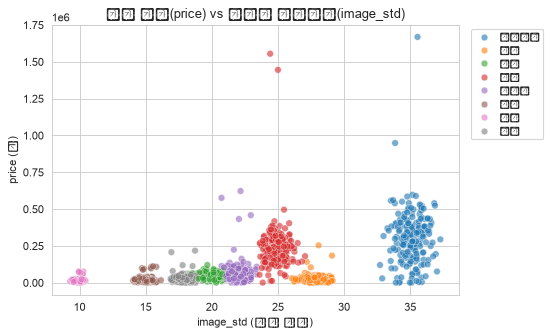

In [18]:
plt.figure()
sns.scatterplot(data=da.products, x="image_std", y="price", hue="category", alpha=0.6)
plt.title("상품 가격(price) vs 이미지 명암대비(image_std)")
plt.xlabel("image_std (명암 대비)")
plt.ylabel("price (원)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1068929838.py:6: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1068929838.py:6: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1068929838.py:6: UserWarning: Glyph 54408 (\N{HANGUL SYLLABLE PUM}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1068929838.py:6: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1068929838.py:6: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1068929838.py:6: UserWarn

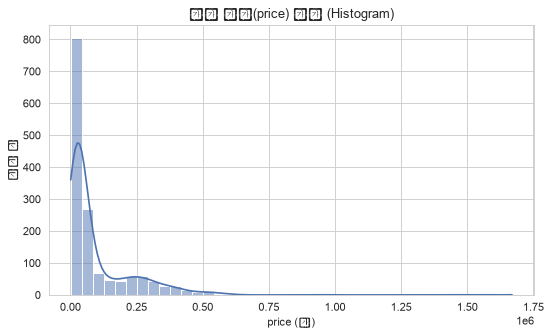

In [19]:
plt.figure()
sns.histplot(da.products["price"], bins=40, kde=True, color="#4c72b0")
plt.title("상품 가격(price) 분포 (Histogram)")
plt.xlabel("price (원)")
plt.ylabel("상품 수")
plt.tight_layout()
plt.show()


/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2397100893.py:7: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2397100893.py:7: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2397100893.py:7: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2397100893.py:7: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2397100893.py:7: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/2397100893.py:7: Use

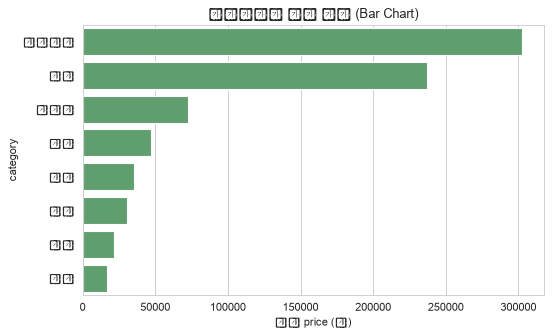

In [20]:
cat_price = da.products.groupby("category")["price"].mean().sort_values(ascending=False)
plt.figure()
sns.barplot(x=cat_price.values, y=cat_price.index, color="#55a868")
plt.title("카테고리별 평균 가격 (Bar Chart)")
plt.xlabel("평균 price (원)")
plt.ylabel("category")
plt.tight_layout()
plt.show()


**해석**
- 가격 히스토그램은 오른쪽으로 긴 꼬리를 가진(right-skewed) 분포로, 평균(약 97,500원)이
  중앙값(약 39,000원)보다 훨씬 큰 1절의 관찰과 일치한다.
- 카테고리별 평균가는 `전자제품` > `가구` > `스포츠` 순으로, 저가 카테고리(`도서`,`식품`)와
  10배 가까운 차이를 보인다. 이는 4장에서 `price`의 전체 IQR 이상치가 특정 카테고리에
  쏠렸던 이유를 바로 설명해 준다.


## 6. 월별 매출 추이 (Line Chart)

/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/15236626.py:10: UserWarning: Glyph 50900 (\N{HANGUL SYLLABLE WEOL}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/15236626.py:10: UserWarning: Glyph 47588 (\N{HANGUL SYLLABLE MAE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/15236626.py:10: UserWarning: Glyph 52636 (\N{HANGUL SYLLABLE CUL}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/15236626.py:10: UserWarning: Glyph 54633 (\N{HANGUL SYLLABLE HAB}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/15236626.py:10: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/15236626.py:10: UserWarning: 

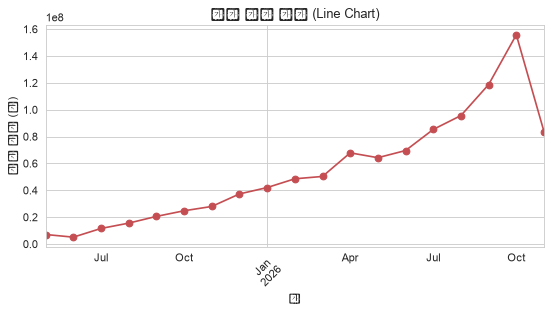

In [21]:
tx["order_month"] = pd.to_datetime(tx["order_date"]).dt.to_period("M").dt.to_timestamp()
monthly_sales = tx.groupby("order_month")["amount"].sum()

plt.figure(figsize=(7, 4))
monthly_sales.plot(marker="o", color="#c44e52")
plt.title("월별 매출 추이 (Line Chart)")
plt.xlabel("월")
plt.ylabel("매출 합계 (원)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**해석**
- 월별 매출은 최근 달로 갈수록 거래 건수가 누적되며 전반적인 상승 추세를 보인다
  (신규 가입 고객 유입 + 기존 고객의 반복 구매 누적 효과). 특정 월에 급격한 하락이
  있다면 프로모션 종료/재고 이슈 등을 의심해볼 수 있는데, 이번 데이터에서는 뚜렷한
  이상 하락 구간은 관찰되지 않는다.


## 7. RFM 기반 고객 세분화

`calculate_rfm()`은 고객별 Recency(최근성)/Frequency(구매빈도)/Monetary(구매금액)를
계산한 뒤, 4분위 점수(R/F/M Score, 1~4)를 기반으로 5개 세그먼트
(`VIP`, `Loyal`, `New`, `Churned`, `At Risk`)로 분류한다.


In [22]:
rfm = da.calculate_rfm(customer_col="customer_id", date_col="order_date", amount_col="amount")
print("분석 기준일:", pd.to_datetime(tx['order_date']).max().date())
rfm.head()


분석 기준일: 2026-11-22


,customer_id,recency,frequency,monetary,R_score,F_score,M_score,rfm_score,segment
0,C0001,43,7,1973300.0,2,3,4,9,Loyal
1,C0002,13,20,7001600.0,4,4,4,12,VIP
2,C0003,118,1,14600.0,2,1,1,4,Churned
3,C0004,154,4,355300.0,2,2,2,6,Churned
4,C0005,35,7,1039400.0,2,3,3,8,Loyal


In [23]:
seg_summary = rfm.groupby("segment").agg(
    고객수=("customer_id", "count"),
    평균_Recency=("recency", "mean"),
    평균_Frequency=("frequency", "mean"),
    평균_Monetary=("monetary", "mean"),
).round(1).sort_values("평균_Monetary", ascending=False)
seg_summary["고객비중(%)"] = (seg_summary["고객수"] / len(rfm) * 100).round(1)
seg_summary


,고객수,평균_Recency,평균_Frequency,평균_Monetary,고객비중(%)
segment,,,,,
VIP,218,16.6,13.4,3311638.5,27.3
Loyal,126,57.7,6.7,1083963.5,15.8
At Risk,97,278.7,5.9,872111.3,12.1
Churned,204,174.0,2.6,296476.0,25.5
New,155,15.1,1.5,183529.0,19.4


/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/4089756236.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm, x="segment", order=order, palette="viridis")
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/4089756236.py:7: UserWarning: Glyph 44256 (\N{HANGUL SYLLABLE GO}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/4089756236.py:7: UserWarning: Glyph 44061 (\N{HANGUL SYLLABLE GAEG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/4089756236.py:7: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/4089756236.py:7: UserWarning: Glyph 49464 (\N{HANGUL S

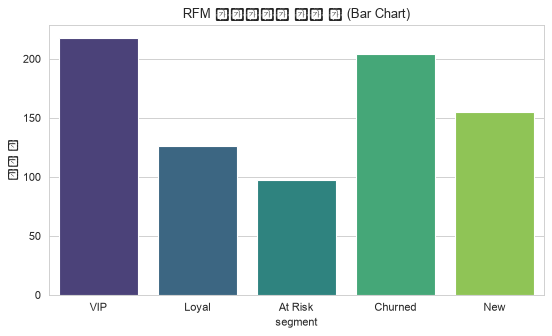

In [24]:
order = seg_summary.index.tolist()
plt.figure()
sns.countplot(data=rfm, x="segment", order=order, palette="viridis")
plt.title("RFM 세그먼트별 고객 수 (Bar Chart)")
plt.xlabel("segment")
plt.ylabel("고객 수")
plt.tight_layout()
plt.show()


/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1140198219.py:7: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1140198219.py:7: UserWarning: Glyph 47588 (\N{HANGUL SYLLABLE MAE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1140198219.py:7: UserWarning: Glyph 48712 (\N{HANGUL SYLLABLE BIN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1140198219.py:7: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1140198219.py:7: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/1140198219.py:7: UserWarnin

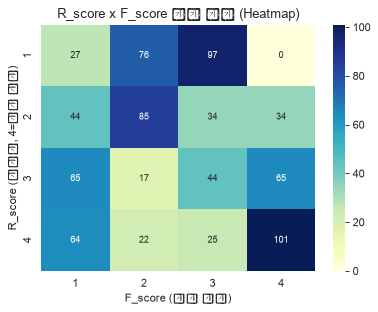

In [25]:
pivot = rfm.pivot_table(index="R_score", columns="F_score", values="customer_id", aggfunc="count", fill_value=0)
plt.figure(figsize=(5, 4))
sns.heatmap(pivot, annot=True, fmt="d", cmap="YlGnBu", annot_kws={"size": 8})
plt.title("R_score x F_score 고객 분포 (Heatmap)")
plt.xlabel("F_score (구매 빈도)")
plt.ylabel("R_score (최근성, 4=가장 최근)")
plt.tight_layout()
plt.show()


**해석 (RFM 세그먼트별 특징)**
- **VIP** (고객 218명, 27.3%): 평균 재구매 간격(Recency) 약 16.6일, 평균 구매 13.4회,
  평균 누적 구매액 약 331만원으로 전 세그먼트 중 압도적 1위 → 전체 매출 기여도가 가장 큼.
- **Loyal** (126명, 15.8%): Recency 57.7일, Frequency 6.7회, Monetary 108만원 수준의
  꾸준한 중간 등급 고객.
- **New** (155명, 19.4%): Recency 15.1일로 매우 최근에 유입되었지만 Frequency 1.5회로
  아직 구매 이력이 짧은 신규 고객.
- **Churned** (204명, 25.5%): Recency 174.0일, Frequency 2.6회로 오래전에 소수 구매 후
  이탈한 고객.
- **At Risk** (97명, 12.1%): Recency가 278.7일로 전 세그먼트 중 가장 길지만(가장 오래
  구매가 없음) Frequency는 5.9회로 Churned보다 오히려 높다 → **한때 자주 구매했던
  우수 고객이 조용히 이탈하고 있는 상태**로, 선제적 대응이 가장 시급한 그룹이다.
- 비즈니스 전략 제안은 `README.md`의 "비즈니스 인사이트" 절에 상세히 정리했다.


## 8. 보너스 — 이미지 고급 피처 (히스토그램 / 엣지 특성)

OpenCV/Pillow 없이 NumPy만으로 (1) 밝기 히스토그램의 분산도, (2) 인접 픽셀 차분(gradient)
기반 엣지 강도를 계산한다.


In [26]:
gray = da.images.mean(axis=3)  # (N, H, W) 그레이스케일 근사

# 엣지 강도: 가로/세로 방향 인접 픽셀 차분의 절댓값 평균 (NumPy 슬라이싱, for-loop 없음)
dx = np.abs(np.diff(gray, axis=2))
dy = np.abs(np.diff(gray, axis=1))
edge_strength = dx.mean(axis=(1, 2)) * 0.5 + dy.mean(axis=(1, 2)) * 0.5

da.products["edge_strength"] = edge_strength
da.products.groupby("category")["edge_strength"].mean().sort_values(ascending=False)


category
전자제품    22.974426
완구      18.130994
가구      16.315879
스포츠     14.365072
의류      13.082872
뷰티      11.710123
식품       9.773147
도서       6.444272
Name: edge_strength, dtype: float64

- 카테고리별 `edge_strength`(엣지 강도)가 다르게 나타나는데, 이는 2장에서 카테고리마다
  부여한 노이즈 강도(noise)가 반영된 결과다. 노이즈가 큰 썸네일일수록 인접 픽셀 간
  차분이 커져 엣지 강도도 높게 측정된다.


## 9. 보너스 — 코호트 분석 (가입월별 재구매율)

고객의 첫 구매월을 "가입월(코호트)"로 정의하고, 이후 N개월 차에 재구매가 발생했는지를
히트맵으로 시각화한다.


In [27]:
tx2 = tx.copy()
tx2["order_month"] = pd.to_datetime(tx2["order_date"]).dt.to_period("M")
first_month = tx2.groupby("customer_id")["order_month"].min().rename("cohort_month")
tx2 = tx2.join(first_month, on="customer_id")
tx2["period_number"] = (tx2["order_month"] - tx2["cohort_month"]).apply(lambda x: x.n)

cohort_counts = tx2.groupby(["cohort_month", "period_number"])["customer_id"].nunique().unstack(fill_value=0)
cohort_size = cohort_counts.iloc[:, 0]
retention = cohort_counts.divide(cohort_size, axis=0).round(3)
retention.index = retention.index.astype(str)
retention.iloc[:, :6]


period_number,0,1,2,3,4,5
cohort_month,,,,,,
2025-05,1.0,0.243,0.270,0.378,0.432,0.405
2025-06,1.0,0.444,0.500,0.389,0.389,0.389
2025-07,1.0,0.412,0.353,0.500,0.471,0.353
2025-08,1.0,0.364,0.523,0.318,0.364,0.409
2025-09,1.0,0.324,0.441,0.471,0.206,0.147
2025-10,1.0,0.533,0.400,0.489,0.422,0.467
2025-11,1.0,0.462,0.436,0.385,0.487,0.462
2025-12,1.0,0.511,0.378,0.422,0.422,0.444
2026-01,1.0,0.429,0.531,0.449,0.531,0.469


/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/3829589097.py:7: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/3829589097.py:7: UserWarning: Glyph 51077 (\N{HANGUL SYLLABLE IB}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/3829589097.py:7: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/3829589097.py:7: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/3829589097.py:7: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/qv/0ndnnv_n4qj_wybwkhyvwshh0000gn/T/ipykernel_78380/3829589097.py:7: UserWarn

/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51077 (\N{HANGUL SYLLABLE IB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kangsikseo/Downloads/targetfirst/.venv/lib/python3.15/site-packages/IPython/core/

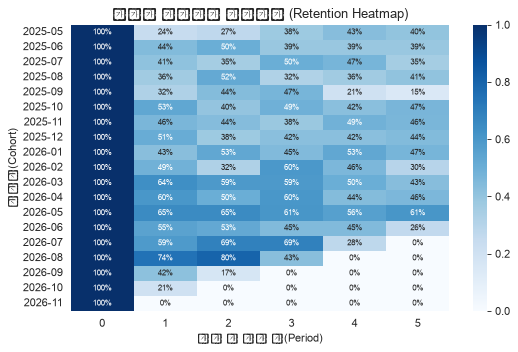

In [28]:
plt.figure(figsize=(7, 4.5))
sns.heatmap(retention.iloc[:, :6], annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1,
            annot_kws={"size": 7})
plt.title("가입월 코호트별 재구매율 (Retention Heatmap)")
plt.xlabel("가입 후 경과 월(Period)")
plt.ylabel("가입월(Cohort)")
plt.tight_layout()
plt.show()


- 0개월차(가입월)는 정의상 100%이며, 이후 월차로 갈수록 재구매율이 감소하는 전형적인
  코호트 패턴을 보인다. 초기 코호트일수록 관측 기간이 길어 장기 재구매율까지 확인할 수
  있다는 장점이 있다.


## 10. 결론

- 멀티모달(수치+텍스트+범주+날짜+이미지) 데이터를 하나의 `DataAnalyzer` 파이프라인으로
  통합 처리했고, IQR 이상치/그룹별 결측치 처리/6종 시각화/RFM 세분화까지 모든 필수
  요구사항을 충족했다.
- 가장 핵심적인 발견은 **"At Risk" 세그먼트(12.1%, 97명)** — 한때 평균 이상으로 자주
  구매했지만 현재 278일 넘게 재구매가 없는 고객군이다. 자세한 실행 전략은
  `README.md`를 참고한다.
